# Takeover results (campaign v3)

**Data: `out/remote_v3`**, campaign v3 (commit 32e29dd, 3000 runs, 10 seeds): SCI 1-A on every PSSCH, leader
aperiodic traffic on dynamic grants, every arm at 0 / 15 / 30 / 45 / 60 background cars. One figure grid per
question: rows = traffic (periodic1tb, aperiodic1tb), columns = scenario (highway, roundabout W, roundabout E).
Error bars / bands: 95 % bootstrap CI over seeds (seeds resampled, ratio of pooled counts).

**Unit**: a (TB, member) pair, inside the run's KPI window. Each leader packet is one TB (the `*1tb` classes).
*Delivered* = the member decoded the TB within the PDB (100 ms periodic, 50 ms aperiodic); this equals `_pkt.csv`
`rx` for every pair. *TB delivery probability* = delivered pairs / pairs (= group PRR); *residual BLER* = 1 − that.

| quantity | definition |
|---|---|
| channel quality (Fig. 1) | SINR of the leader's **first** transmission of the TB at that member (`_att.csv`). A member that missed the SCI 1-A of that copy has no SINR: separate point "SCI missed". Pooled over loads. |
| helper failure (Fig. 2–4) | the TB's helper (named in SCI-2A, `_hsel.csv`) did not decode the leader's first transmission, so it cannot send its assigned retransmission. Probability = share of TBs in a **2 s window** of one run; the windows are binned. Leader-only arms (R1, R2, R3) have no helper: they are placed at the helper failure rate R6 measured in the same scenario, load, seed and window (same trace), drawn with hollow markers. |
| resource efficiency (Fig. 3) | delivered pairs / 8 (TB-equivalents delivered to the group) per subchannel-slot the leader **reserved** (`_grants.csv`, SB-SPS prorated per period; the helper relays in the leader's handed slots, so this is the platoon's whole allocation). Fig. 3b: per subchannel-slot **transmitted** (leader + helper). PSFCH resources are not counted here (`paper_data.cost_metrics`). |
| takeover attempt (Fig. 4) | one leader transmission in a slot it had handed to the helper (`_ltx.csv origin`): **helper NACK** (origin 1) or **fallback**: no helper SCI detected in the handed slot (origin 2). R5 (Option 1) and R6 (Option 2) only. |
| recovery | an attempt *recovers* the TB if at least one member that lacked the TB decodes it at that transmission (its first decode, on the leader's copy). $P_\mathrm{recovery}$ = recovering attempts / attempts. Also: member rescue rate = members rescued / members lacking at the attempt; attempts with no member lacking (fallback false alarm) count as attempts. |
| takeover fraction | TBs with at least one takeover attempt / TBs. |
| latency | generation → first decode at the member (`_pkt.csv delay_ms`, histogram 0.25 ms). CDF counts lost pairs as never delivered (curve ends at the delivery probability); p95 is over delivered pairs. |


In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
HERE = os.path.abspath('.')
sys.path.insert(0, HERE)
import takeover_data as TD
OUT = os.environ.get('STUDY_OUT', '/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/out/remote_v3')
CACHE = os.path.join(HERE, 'out', 'cache_takeover_v3')
FIG = os.path.join(HERE, 'figures', 'takeover_v3'); os.makedirs(FIG, exist_ok=True)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
D = TD.collect(OUT, CACHE, jobs=4)
SIN, WIN, LAT = D['sinr'], D['win'], D['lat']
NMEM = TD.NMEM

# --- selection: change here
LOADS = [0, 15, 30, 45, 60]                              # loads pooled in Fig. 1-4
ARMS_ALL = ['R1', 'R2', 'R3', 'R4', 'R4.1', 'R4.2', 'R5', 'R6']
ARMS_MAIN = ['R1', 'R3', 'R4', 'R4.2', 'R5', 'R6']      # Fig. 1, latency
HELPER_ARMS = ['R4', 'R4.1', 'R4.2', 'R5', 'R6']
LEADER_REF = ['R1', 'R3']                                # leader-only references in Fig. 2 / 3 (x from R6)
TO_ARMS = ['R5', 'R6']
HF_EDGES = [0, .1, .2, .3, .4, .5, .6, .8, 1.0001]
MIN_PAIRS = 200                                          # a bin is drawn only with >= this many pairs (pooled)

SCS = ['hwy', 'rbt', 'rbtE']; TRS = ['periodic1tb', 'aperiodic1tb']
SCN = {'hwy': 'Highway', 'rbt': 'Roundabout W (curve)', 'rbtE': 'Roundabout E (curve)'}
TRN = {'periodic1tb': 'periodic (100 ms)', 'aperiodic1tb': 'aperiodic'}
LABEL = {'R1': 'R1 leader blind', 'R2': 'R2 leader Opt1', 'R3': 'R3 leader Opt2',
         'R4': 'R4 Kuo blind', 'R4.1': 'R4.1 Kuo+Opt1', 'R4.2': 'R4.2 Kuo+Opt2',
         'R5': 'R5 Kuo+Opt1+takeover', 'R6': 'R6 Kuo+Opt2+takeover'}
STYLE = {'R1': ('black', '-', 1.5), 'R2': ('gray', '--', 1.5), 'R3': ('silver', ':', 1.5),
         'R4': ('tab:blue', '-', 2.0), 'R4.1': ('tab:blue', '--', 1.5), 'R4.2': ('tab:blue', ':', 1.5),
         'R5': ('tab:red', '-', 2.5), 'R6': ('tab:green', '-', 2.5)}
MARK = {'R1': 'o', 'R2': 'o', 'R3': 'o', 'R4': 's', 'R4.1': 's', 'R4.2': 's', 'R5': '^', 'R6': '^'}
RNG = np.random.default_rng(1)
B = 1000


def boot_ratio(g, num, den):
    """pooled ratio sum(num)/sum(den) of frame g and its 95 % CI, resampling seeds."""
    s = g.groupby('seed')[[num, den]].sum()
    N, Dn = s[num].values.astype(float), s[den].values.astype(float)
    r = N.sum() / Dn.sum() if Dn.sum() > 0 else np.nan
    if len(s) < 2 or Dn.sum() == 0:
        return r, np.nan, np.nan
    idx = RNG.integers(0, len(s), (B, len(s)))
    with np.errstate(invalid='ignore', divide='ignore'):
        bs = N[idx].sum(1) / Dn[idx].sum(1)
    lo, hi = np.nanpercentile(bs, [2.5, 97.5])
    return r, lo, hi


def grid(title, ylabel, xlabel, sharey=True, figsize=(15, 7.5)):
    fig, ax = plt.subplots(2, 3, figsize=figsize, sharey=sharey, squeeze=False)
    for i, tr in enumerate(TRS):
        for j, sc in enumerate(SCS):
            a = ax[i, j]; a.grid(alpha=.3, lw=.5)
            a.set_title(f'{SCN[sc]}, {TRN[tr]}', fontsize=10)
            if j == 0: a.set_ylabel(ylabel)
            if i == 1: a.set_xlabel(xlabel)
    fig.suptitle(title, fontsize=12)
    return fig, ax


def legend(fig, arms, extra=()):
    h = [Line2D([], [], color=STYLE[a][0], ls=STYLE[a][1], lw=STYLE[a][2], marker=MARK[a], label=LABEL[a])
         for a in arms] + list(extra)
    fig.legend(handles=h, loc='lower center', ncol=min(len(h), 5), fontsize=9, frameon=False)
    fig.tight_layout(rect=(0, .07, 1, .96))


def save(fig, name):
    fig.savefig(os.path.join(FIG, name + '.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(FIG, name + '.png'), dpi=130, bbox_inches='tight')


## Data check
Runs per arm and cell, and the group PRR of these tables against `paper_data.collect_folder` (`paper_v2/analysis/cache_v3`, mean of the member PRRs): must agree to rounding.

In [2]:
runs = WIN.drop_duplicates(['arm', 'sc', 'tr', 'nbg', 'seed'])
display(runs.groupby(['arm', 'sc', 'tr']).size().unstack(['sc', 'tr']))
g = WIN.groupby(['arm', 'sc', 'tr', 'nbg', 'seed'])[['n_deliv', 'n_pairs', 'n_notx']].sum()
g['prr'] = g.n_deliv / g.n_pairs
ref = []
for f in sorted(os.listdir(os.path.join(HERE, 'paper_v2', 'analysis', 'cache_v3'))):
    if f.startswith('remote_v3__') and f.endswith('_runs.csv'):
        ref.append(pd.read_csv(os.path.join(HERE, 'paper_v2', 'analysis', 'cache_v3', f)))
ref = pd.concat(ref).set_index(['arm', 'sc', 'tr', 'nbg', 'seed']).prr
j = g.join(ref.rename('prr_ref'), how='inner')
print(f'{len(j)} runs compared, max |prr - prr_ref| = {(j.prr - j.prr_ref).abs().max():.2e}; '
      f'packets never transmitted: {int(g.n_notx.sum())} of {int(WIN.n_pkt.sum())}')


sc              hwy                      rbt                     rbtE            
tr     aperiodic1tb periodic1tb aperiodic1tb periodic1tb aperiodic1tb periodic1tb
arm                                                                              
R1               50          50           50          50           50          50
R1_bsc           50          50           50          50           50          50
R2               50          50           50          50           50          50
R3               50          50           50          50           50          50
R4               50          50           50          50           50          50
R4.1             50          50           50          50           50          50
R4.2             50          50           50          50           50          50
R4_bsc           50          50           50          50           50          50
R5               50          50           50          50           50          50
R6               50          50           50          50           50          50

3000 runs compared, max |prr - prr_ref| = 2.22e-16; packets never transmitted: 0 of 1134350


## Figure 1 — Residual BLER versus channel quality
x: SINR of the leader's first transmission of the TB at the member (2 dB bins, edges clipped at −12 and 40 dB);
leftmost point: the member missed the SCI 1-A of the first transmission (no SINR). y: residual BLER after every
allowed retransmission and relay (pair not delivered within the PDB), log scale; bins with no loss are not drawn.
Pooled over the loads in `LOADS`. The first transmission is the leader's in every arm, so the x-axis is the same
link for every scheme.

The floor of R4 / R4.2 at high SINR (~1e-2) is real: in every arm ~3.5 % of first copies above 25 dB still fail
(`_att.csv` status 2: a failed SCI-2A or interference on part of the band, which the RB-averaged SINR hides; e.g.
highway aperiodic 60 cars, seeds 1-4: R4 107 of 3034, R3 85 of 3281). Leader HARQ and the takeover arms
retransmit; R4 / R4.2 depend on the single helper copy, and when the helper also missed the TB nothing follows
(never decoded: R4 98, R4.2 71, R6 12, R3 3 of those pairs).

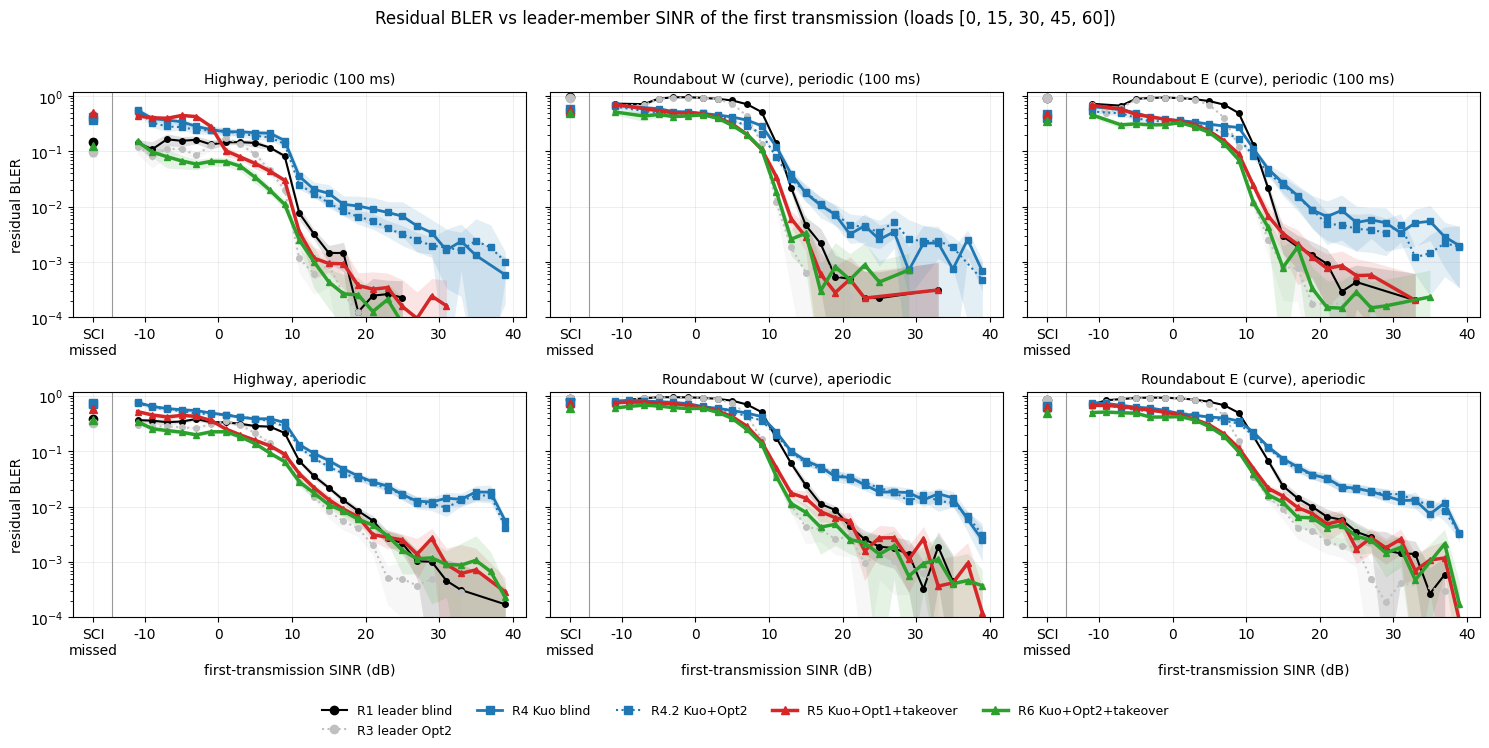

In [3]:
XMISS = TD.SINR_LO - 5
def fig1(loads=LOADS, arms=ARMS_MAIN, name='fig1_bler_vs_sinr', hfail=None):
    s = SIN[SIN.nbg.isin(loads) & SIN.arm.isin(arms)]
    if hfail is not None:
        s = s[s.hfail == hfail]
    fig, ax = grid(f'Residual BLER vs leader-member SINR of the first transmission (loads {loads})',
                   'residual BLER', 'first-transmission SINR (dB)')
    rows = []
    for i, tr in enumerate(TRS):
        for j, sc in enumerate(SCS):
            a = ax[i, j]
            for arm in arms:
                g = s[(s.sc == sc) & (s.tr == tr) & (s.arm == arm)].assign(n_lost=lambda x: x.n_pairs - x.n_deliv)
                pts = []
                for b, gb in g.groupby('bin'):
                    if gb.n_pairs.sum() < MIN_PAIRS: continue
                    r, lo, hi = boot_ratio(gb, 'n_lost', 'n_pairs')
                    x = XMISS if b == TD.SINR_MISS else b + TD.SINR_STEP / 2
                    pts.append((x, r, lo, hi, gb.n_pairs.sum()))
                    rows.append(dict(sc=sc, tr=tr, arm=arm, bin=b, bler=r, lo=lo, hi=hi, pairs=gb.n_pairs.sum()))
                if not pts: continue
                p = pd.DataFrame(pts, columns=['x', 'r', 'lo', 'hi', 'n']).sort_values('x')
                p = p[p.r > 0]
                col, ls, lw = STYLE[arm]
                m = p.x > XMISS
                a.plot(p.x[m], p.r[m], ls=ls, color=col, lw=lw, marker=MARK[arm], ms=4)
                a.fill_between(p.x[m], p.lo[m].clip(lower=1e-5), p.hi[m], color=col, alpha=.12, lw=0)
                mm = p[~m]
                if len(mm):
                    a.errorbar(mm.x.values, mm.r.values, yerr=[(mm.r - mm.lo).values, (mm.hi - mm.r).values], fmt=MARK[arm], color=col, ms=6,
                               capsize=2, lw=1)
            a.set_yscale('log'); a.set_ylim(1e-4, 1.2)
            a.axvline(XMISS + 2.5, color='0.6', lw=.8)
            a.set_xticks([XMISS] + list(range(-10, 41, 10)))
            a.set_xticklabels(['SCI\nmissed'] + [str(v) for v in range(-10, 41, 10)])
    legend(fig, arms); save(fig, name); plt.show()
    return pd.DataFrame(rows)

F1 = fig1()
F1.to_csv(os.path.join(FIG, 'fig1_bler_vs_sinr.csv'), index=False)


Share of pairs per SINR bin (pooled, R6): how much of the traffic sits where the schemes differ.

In [4]:
s = SIN[(SIN.arm == 'R6') & SIN.nbg.isin(LOADS)]
cut = pd.cut(s.bin.where(s.bin != TD.SINR_MISS, -100), [-101, -99, 0, 10, 20, 100],
             labels=['SCI missed', '< 0 dB', '0-10 dB', '10-20 dB', '>= 20 dB'])
t = s.assign(c=cut).groupby(['sc', 'tr', 'c'], observed=False).n_pairs.sum().unstack('c')
display((t.div(t.sum(1), axis=0) * 100).round(1))


c                  SCI missed  < 0 dB  0-10 dB  10-20 dB  >= 20 dB
sc   tr                                                           
hwy  aperiodic1tb         5.8     6.5     19.2      34.9      33.6
     periodic1tb          2.4     3.7     15.5      36.3      42.1
rbt  aperiodic1tb        15.1    16.4     18.6      17.1      32.8
     periodic1tb         12.4    12.6     21.5      16.2      37.4
rbtE aperiodic1tb        12.7    13.9     18.2      19.6      35.6
     periodic1tb         10.0    10.3     20.0      19.1      40.6

Same figure at 0 and at 60 background cars (interference changes how SINR maps to BLER: at 60 cars a copy with the same first-copy SINR meets more collisions on its retransmissions).

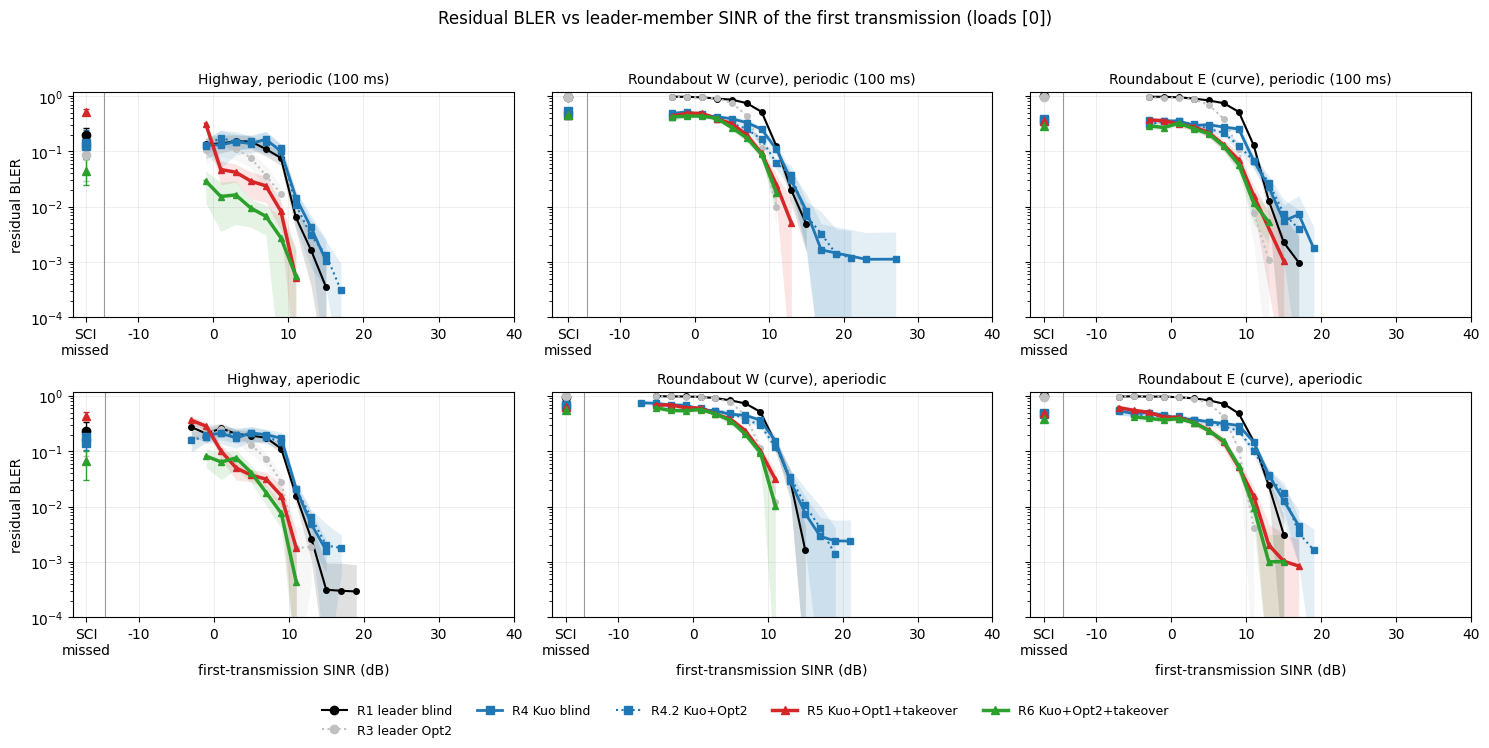

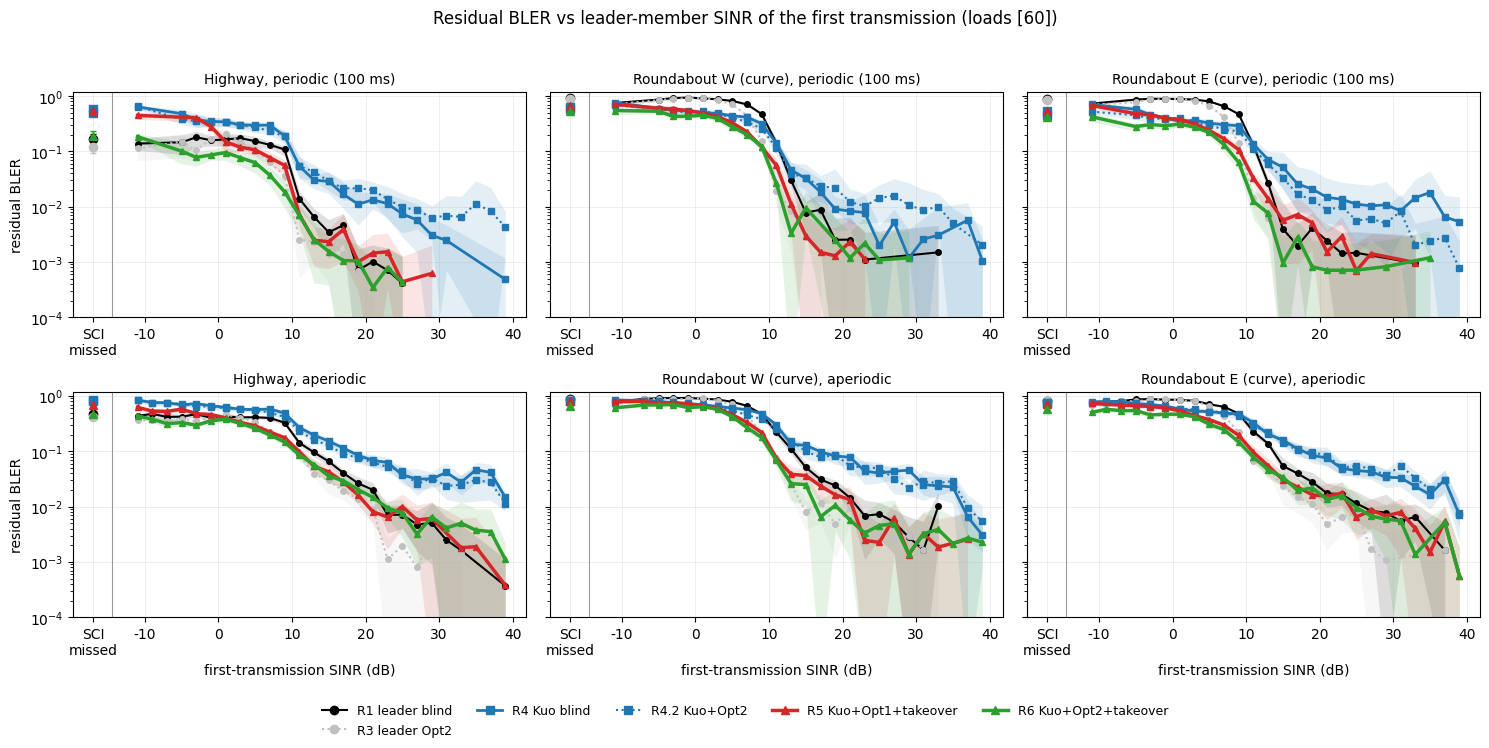

In [5]:
_ = fig1(loads=[0], name='fig1_bler_vs_sinr_0cars')
_ = fig1(loads=[60], name='fig1_bler_vs_sinr_60cars')


## Figure 2 — TB delivery probability versus helper failure probability
x: share of TBs (2 s window of one run) whose helper missed the leader's first transmission; windows binned
(`HF_EDGES`), each point at the TB-weighted mean x of its bin. y: TB delivery probability of the pairs in those
windows. Helper arms use their own helper; leader-only references (hollow) the R6 helper of the same window.
The x-range comes from the data: blockage on the curve, interference at high load.

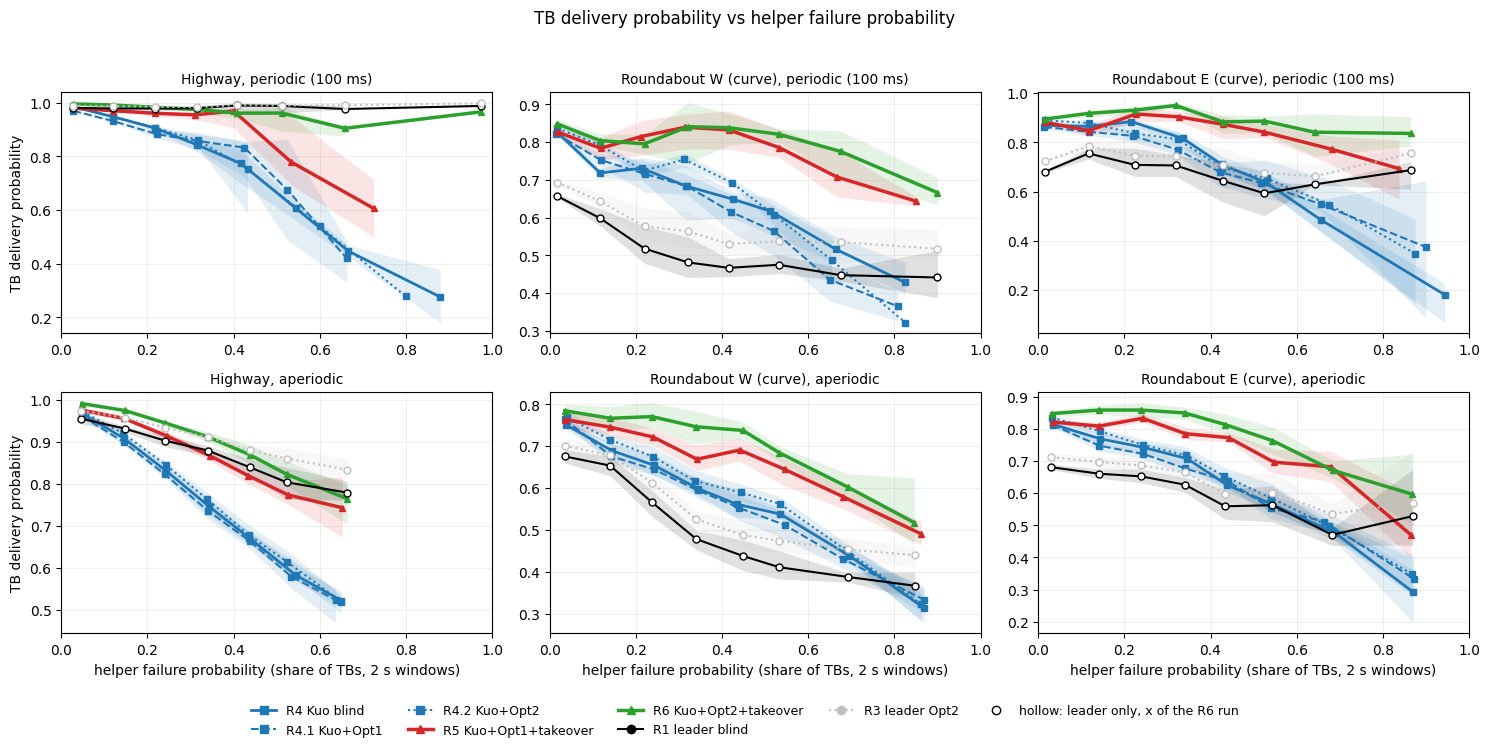

In [6]:
def hf_frame(arms):
    w = WIN[WIN.nbg.isin(LOADS)].copy()
    ref = w[w.arm == 'R6'].set_index(['sc', 'tr', 'nbg', 'seed', 'w'])[['n_hfail', 'n_helper']]
    out = []
    for arm in arms:
        x = w[w.arm == arm]
        if arm in HELPER_ARMS:
            x = x.assign(hf=x.n_hfail / x.n_helper.replace(0, np.nan))
        else:
            r = ref.reindex(pd.MultiIndex.from_frame(x[['sc', 'tr', 'nbg', 'seed', 'w']]))
            x = x.assign(hf=(r.n_hfail / r.n_helper.replace(0, np.nan)).values)
        out.append(x[x.hf.notna()])
    x = pd.concat(out)
    x['hbin'] = pd.cut(x.hf, HF_EDGES, right=False, labels=False)
    x['hf_w'] = x.hf * x.n_pkt
    return x

def fig_vs_hf(num, den, ylabel, title, name, arms, ref_arms=LEADER_REF, ylim=None):
    x = hf_frame(arms + ref_arms)
    fig, ax = grid(title, ylabel, 'helper failure probability (share of TBs, 2 s windows)', sharey=False)
    rows = []
    for i, tr in enumerate(TRS):
        for j, sc in enumerate(SCS):
            a = ax[i, j]
            for arm in arms + ref_arms:
                g = x[(x.sc == sc) & (x.tr == tr) & (x.arm == arm)]
                pts = []
                for b, gb in g.groupby('hbin'):
                    if gb.n_pairs.sum() < MIN_PAIRS: continue
                    r, lo, hi = num(gb) if callable(num) else boot_ratio(gb, num, den)
                    pts.append((gb.hf_w.sum() / gb.n_pkt.sum(), r, lo, hi))
                    rows.append(dict(sc=sc, tr=tr, arm=arm, hbin=b, hf=pts[-1][0], y=r, lo=lo, hi=hi,
                                     pairs=gb.n_pairs.sum(), windows=len(gb)))
                if not pts: continue
                p = pd.DataFrame(pts, columns=['x', 'r', 'lo', 'hi'])
                col, ls, lw = STYLE[arm]
                hollow = arm in ref_arms
                a.plot(p.x, p.r, ls=ls, color=col, lw=lw, marker=MARK[arm], ms=5,
                       mfc='white' if hollow else col)
                a.fill_between(p.x, p.lo, p.hi, color=col, alpha=.12, lw=0)
            a.set_xlim(0, 1)
            if ylim: a.set_ylim(*ylim)
    legend(fig, arms + ref_arms, [Line2D([], [], color='k', marker='o', mfc='white', ls='',
                                         label='hollow: leader only, x of the R6 run')])
    save(fig, name); plt.show()
    out = pd.DataFrame(rows); out.to_csv(os.path.join(FIG, name + '.csv'), index=False)
    return out

F2 = fig_vs_hf('n_deliv', 'n_pairs', 'TB delivery probability', 'TB delivery probability vs helper failure probability',
               'fig2_delivery_vs_helper_failure', HELPER_ARMS)


**Per-TB view of the same question.** Delivery probability of the pairs of TBs whose helper failed vs TBs
whose helper decoded the first copy (no windows), pooled over `LOADS`, with seed CI. The gap between "helper
failed" and "helper ok" is what the takeover has to close; the leader-only arms have no row.

In [7]:
def cond_table(loads=LOADS):
    w = WIN[WIN.nbg.isin(loads) & WIN.arm.isin(HELPER_ARMS)]
    rows = []
    for (sc, tr, arm), g in w.groupby(['sc', 'tr', 'arm']):
        f = boot_ratio(g, 'n_deliv_hfail', 'n_pairs_hfail'); o = boot_ratio(g, 'n_deliv_hok', 'n_pairs_hok')
        rows.append(dict(sc=sc, tr=tr, arm=arm, p_hfail=g.n_hfail.sum() / g.n_helper.sum(),
                         deliv_hfail=f[0], ci_hfail=f'[{f[1]:.3f}, {f[2]:.3f}]',
                         deliv_hok=o[0], ci_hok=f'[{o[1]:.3f}, {o[2]:.3f}]'))
    return pd.DataFrame(rows).set_index(['sc', 'tr', 'arm']).round(3)

for L in (LOADS, [0], [60]):
    display(Markdown(f'loads {L}')); T = cond_table(L); display(T)
    T.to_csv(os.path.join(FIG, f'tab_delivery_given_helper_{"all" if L == LOADS else L[0]}.csv'))


loads [0, 15, 30, 45, 60]

p_hfail  deliv_hfail        ci_hfail  deliv_hok          ci_hok
sc   tr           arm                                                                  
hwy  aperiodic1tb R4      0.232        0.369  [0.343, 0.395]      0.975  [0.972, 0.977]
                  R4.1    0.228        0.381  [0.359, 0.403]      0.960  [0.958, 0.962]
                  R4.2    0.226        0.390  [0.365, 0.416]      0.983  [0.982, 0.985]
                  R5      0.226        0.749  [0.727, 0.773]      0.963  [0.960, 0.965]
                  R6      0.228        0.803  [0.785, 0.822]      0.984  [0.983, 0.985]
     periodic1tb  R4      0.101        0.571  [0.527, 0.606]      0.993  [0.992, 0.994]
                  R4.1    0.092        0.590  [0.556, 0.622]      0.977  [0.976, 0.979]
                  R4.2    0.094        0.584  [0.558, 0.607]      0.996  [0.995, 0.997]
                  R5      0.088        0.903  [0.879, 0.923]      0.979  [0.977, 0.981]
                  R6      0.094        0.942  [0.933, 0.951]      0.996  [0.995, 0.997]
rbt  aperiodic1tb R4      0.227        0.229  [0.221, 0.238]      0.784  [0.780, 0.788]
                  R4.1    0.228        0.232  [0.226, 0.240]      0.780  [0.774, 0.786]
                  R4.2    0.222        0.236  [0.229, 0.242]      0.809  [0.802, 0.815]
                  R5      0.232        0.495  [0.484, 0.506]      0.780  [0.774, 0.788]
                  R6      0.220        0.532  [0.517, 0.548]      0.813  [0.807, 0.818]
     periodic1tb  R4      0.082        0.303  [0.284, 0.317]      0.829  [0.825, 0.833]
                  R4.1    0.086        0.288  [0.273, 0.301]      0.828  [0.822, 0.835]
                  R4.2    0.077        0.302  [0.285, 0.320]      0.851  [0.847, 0.856]
                  R5      0.073        0.653  [0.623, 0.684]      0.831  [0.826, 0.835]
                  R6      0.083        0.677  [0.664, 0.689]      0.849  [0.845, 0.854]
rbtE aperiodic1tb R4      0.186        0.280  [0.268, 0.289]      0.855  [0.851, 0.860]
                  R4.1    0.189        0.284  [0.268, 0.299]      0.842  [0.839, 0.846]
                  R4.2    0.193        0.284  [0.269, 0.299]      0.878  [0.875, 0.881]
                  R5      0.185        0.593  [0.570, 0.616]      0.847  [0.843, 0.853]
                  R6      0.186        0.637  [0.624, 0.649]      0.882  [0.879, 0.886]
     periodic1tb  R4      0.076        0.379  [0.351, 0.410]      0.890  [0.888, 0.892]
                  R4.1    0.073        0.396  [0.375, 0.417]      0.880  [0.876, 0.883]
                  R4.2    0.071        0.397  [0.355, 0.427]      0.908  [0.905, 0.911]
                  R5      0.080        0.766  [0.750, 0.783]      0.886  [0.881, 0.890]
                  R6      0.081        0.812  [0.790, 0.836]      0.908  [0.907, 0.910]

loads [0]

p_hfail  deliv_hfail        ci_hfail  deliv_hok          ci_hok
sc   tr           arm                                                                  
hwy  aperiodic1tb R4      0.101        0.701  [0.684, 0.715]      0.996  [0.994, 0.997]
                  R4.1    0.093        0.703  [0.680, 0.725]      0.985  [0.983, 0.987]
                  R4.2    0.099        0.715  [0.687, 0.738]      0.996  [0.994, 0.998]
                  R5      0.098        0.967  [0.959, 0.977]      0.984  [0.982, 0.986]
                  R6      0.097        0.969  [0.959, 0.980]      0.996  [0.994, 0.998]
     periodic1tb  R4      0.071        0.766  [0.753, 0.780]      0.998  [0.998, 0.999]
                  R4.1    0.073        0.760  [0.744, 0.773]      0.985  [0.983, 0.987]
                  R4.2    0.073        0.766  [0.745, 0.786]      0.999  [0.998, 0.999]
                  R5      0.067        0.974  [0.970, 0.979]      0.986  [0.985, 0.988]
                  R6      0.071        0.984  [0.981, 0.988]      0.999  [0.999, 1.000]
rbt  aperiodic1tb R4      0.142        0.320  [0.307, 0.334]      0.809  [0.801, 0.817]
                  R4.1    0.147        0.315  [0.302, 0.328]      0.810  [0.803, 0.818]
                  R4.2    0.147        0.314  [0.304, 0.324]      0.829  [0.824, 0.834]
                  R5      0.163        0.566  [0.515, 0.625]      0.818  [0.810, 0.827]
                  R6      0.144        0.609  [0.563, 0.661]      0.834  [0.828, 0.839]
     periodic1tb  R4      0.052        0.353  [0.331, 0.379]      0.840  [0.835, 0.846]
                  R4.1    0.053        0.369  [0.334, 0.403]      0.850  [0.846, 0.855]
                  R4.2    0.053        0.379  [0.353, 0.400]      0.869  [0.862, 0.876]
                  R5      0.055        0.744  [0.705, 0.785]      0.853  [0.850, 0.858]
                  R6      0.060        0.743  [0.693, 0.795]      0.864  [0.861, 0.866]
rbtE aperiodic1tb R4      0.091        0.430  [0.399, 0.463]      0.886  [0.878, 0.894]
                  R4.1    0.102        0.383  [0.351, 0.407]      0.886  [0.880, 0.890]
                  R4.2    0.110        0.403  [0.378, 0.429]      0.905  [0.901, 0.908]
                  R5      0.108        0.675  [0.640, 0.716]      0.890  [0.887, 0.894]
                  R6      0.098        0.717  [0.677, 0.758]      0.907  [0.903, 0.912]
     periodic1tb  R4      0.052        0.469  [0.429, 0.511]      0.905  [0.902, 0.907]
                  R4.1    0.052        0.516  [0.489, 0.546]      0.908  [0.903, 0.912]
                  R4.2    0.050        0.454  [0.417, 0.501]      0.920  [0.915, 0.925]
                  R5      0.050        0.838  [0.797, 0.889]      0.912  [0.907, 0.917]
                  R6      0.049        0.819  [0.772, 0.864]      0.925  [0.924, 0.927]

loads [60]

p_hfail  deliv_hfail        ci_hfail  deliv_hok          ci_hok
sc   tr           arm                                                                  
hwy  aperiodic1tb R4      0.397        0.278  [0.252, 0.299]      0.935  [0.922, 0.947]
                  R4.1    0.381        0.273  [0.247, 0.297]      0.910  [0.898, 0.921]
                  R4.2    0.375        0.274  [0.246, 0.302]      0.958  [0.949, 0.966]
                  R5      0.377        0.624  [0.590, 0.661]      0.922  [0.913, 0.931]
                  R6      0.383        0.694  [0.674, 0.719]      0.956  [0.951, 0.962]
     periodic1tb  R4      0.136        0.452  [0.408, 0.492]      0.983  [0.979, 0.987]
                  R4.1    0.131        0.448  [0.403, 0.498]      0.964  [0.959, 0.969]
                  R4.2    0.137        0.424  [0.390, 0.455]      0.991  [0.988, 0.993]
                  R5      0.131        0.818  [0.761, 0.876]      0.970  [0.966, 0.973]
                  R6      0.135        0.901  [0.881, 0.922]      0.992  [0.989, 0.995]
rbt  aperiodic1tb R4      0.299        0.187  [0.168, 0.207]      0.757  [0.740, 0.773]
                  R4.1    0.318        0.197  [0.180, 0.215]      0.743  [0.730, 0.757]
                  R4.2    0.301        0.191  [0.172, 0.209]      0.784  [0.768, 0.797]
                  R5      0.305        0.436  [0.407, 0.459]      0.738  [0.718, 0.760]
                  R6      0.305        0.486  [0.463, 0.510]      0.791  [0.778, 0.803]
     periodic1tb  R4      0.112        0.256  [0.239, 0.276]      0.813  [0.802, 0.823]
                  R4.1    0.109        0.254  [0.234, 0.273]      0.798  [0.773, 0.820]
                  R4.2    0.120        0.233  [0.195, 0.274]      0.837  [0.821, 0.855]
                  R5      0.096        0.567  [0.532, 0.608]      0.792  [0.774, 0.810]
                  R6      0.135        0.633  [0.594, 0.668]      0.833  [0.824, 0.842]
rbtE aperiodic1tb R4      0.297        0.214  [0.194, 0.234]      0.818  [0.806, 0.830]
                  R4.1    0.299        0.226  [0.197, 0.255]      0.794  [0.774, 0.811]
                  R4.2    0.312        0.224  [0.201, 0.249]      0.841  [0.830, 0.854]
                  R5      0.290        0.520  [0.484, 0.561]      0.798  [0.786, 0.809]
                  R6      0.289        0.577  [0.543, 0.610]      0.854  [0.840, 0.869]
     periodic1tb  R4      0.102        0.316  [0.278, 0.365]      0.874  [0.866, 0.881]
                  R4.1    0.105        0.313  [0.281, 0.350]      0.844  [0.826, 0.860]
                  R4.2    0.096        0.345  [0.301, 0.385]      0.895  [0.886, 0.903]
                  R5      0.100        0.738  [0.706, 0.766]      0.858  [0.844, 0.872]
                  R6      0.105        0.769  [0.717, 0.821]      0.895  [0.886, 0.905]

## Figure 3 — Resource efficiency versus helper failure probability
y: TB-equivalents delivered to the group (delivered pairs / 8) per **reserved** subchannel-slot (10 PRB × 1 slot).
Same windows and bins as Fig. 2. A scheme that buys reliability with extra resources moves down here.
Fig. 3b: per **transmitted** subchannel-slot (unused reservations not counted).

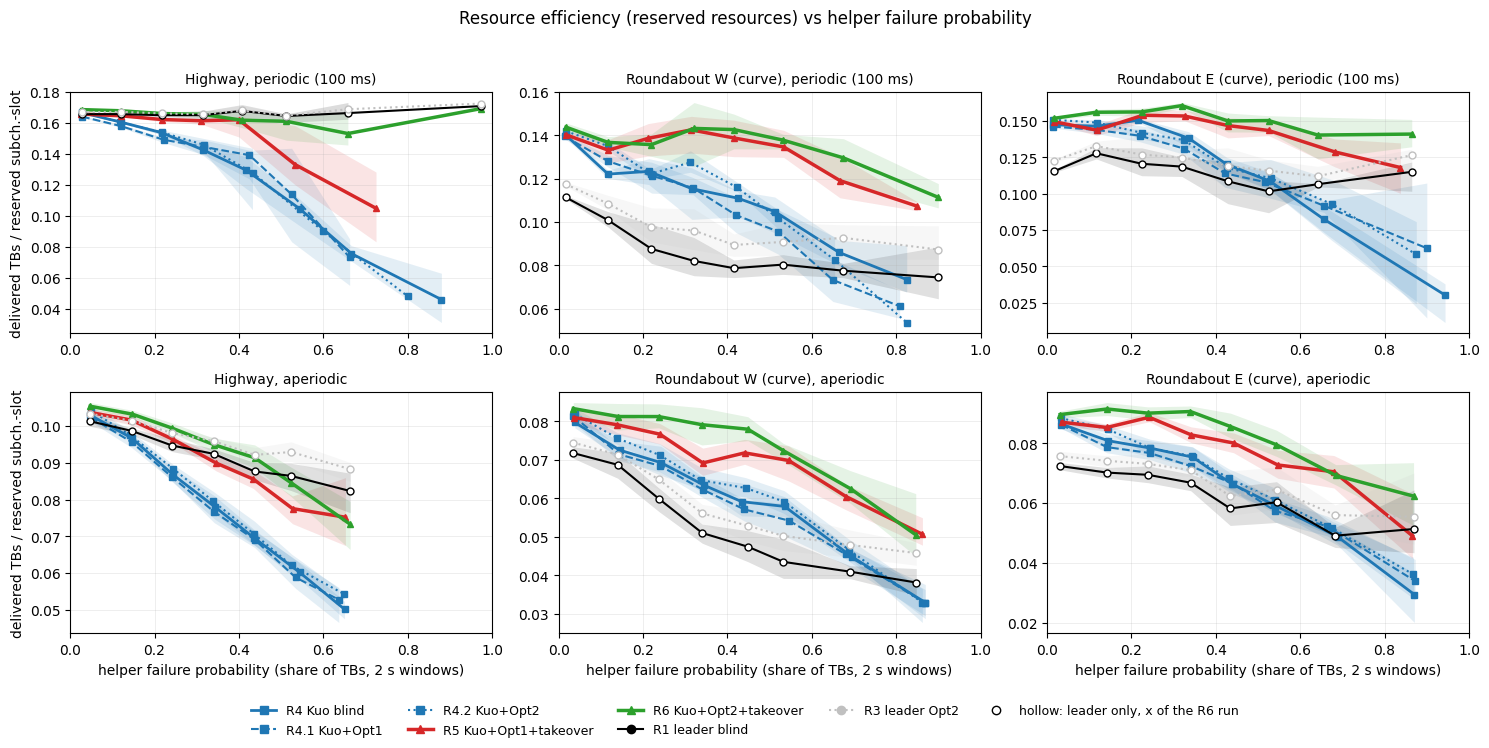

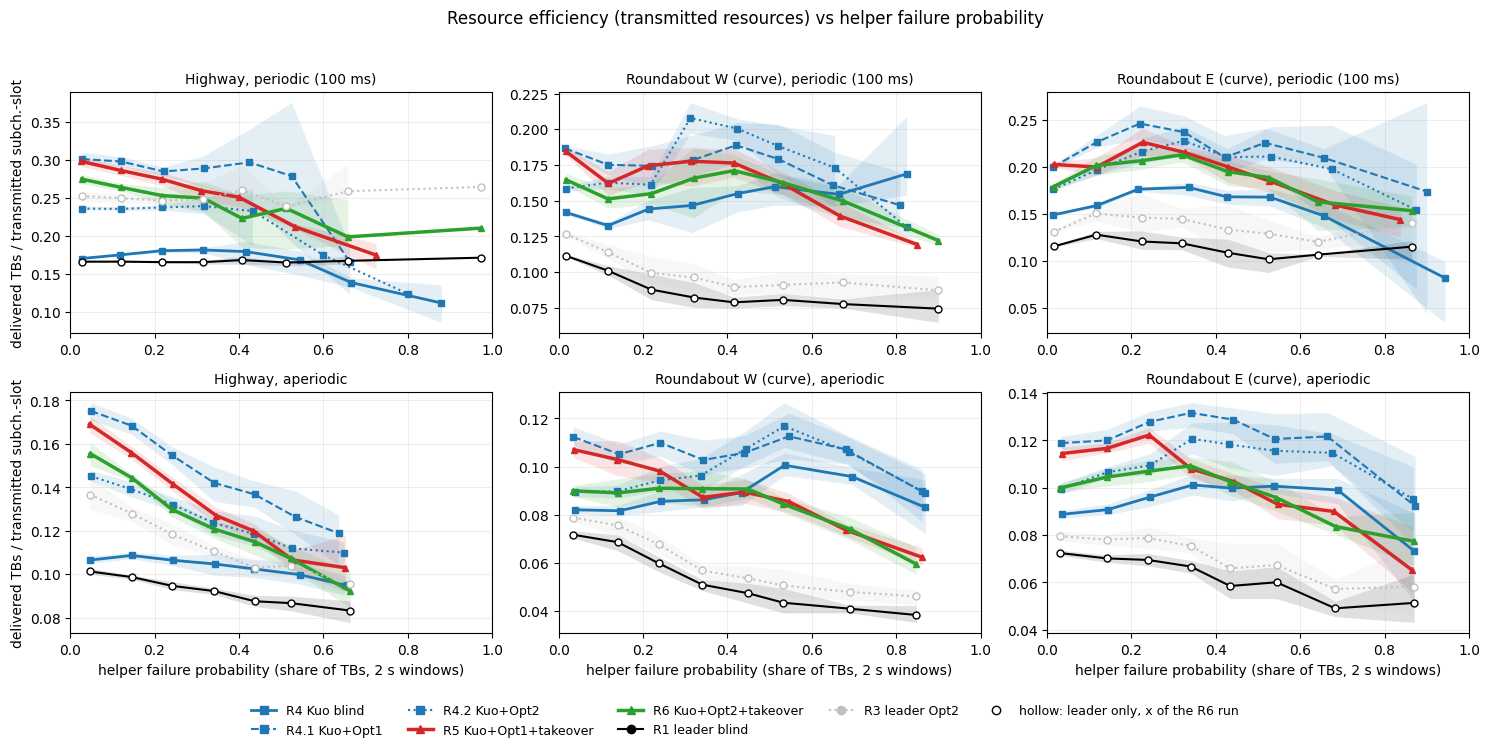

In [8]:
for (col_den, nm, lab) in (('ss_resv', 'fig3_efficiency_reserved_vs_helper_failure', 'reserved'),
                          ('ss_tx', 'fig3b_efficiency_tx_vs_helper_failure', 'transmitted')):
    WIN['tbeq'] = WIN.n_deliv / NMEM
    F3 = fig_vs_hf('tbeq', col_den, f'delivered TBs / {lab} subch.-slot',
                   f'Resource efficiency ({lab} resources) vs helper failure probability', nm, HELPER_ARMS)


Efficiency and delivery per load (whole runs, no windows): delivered TBs per reserved / transmitted subchannel-slot, mean over the cell, seed CI.

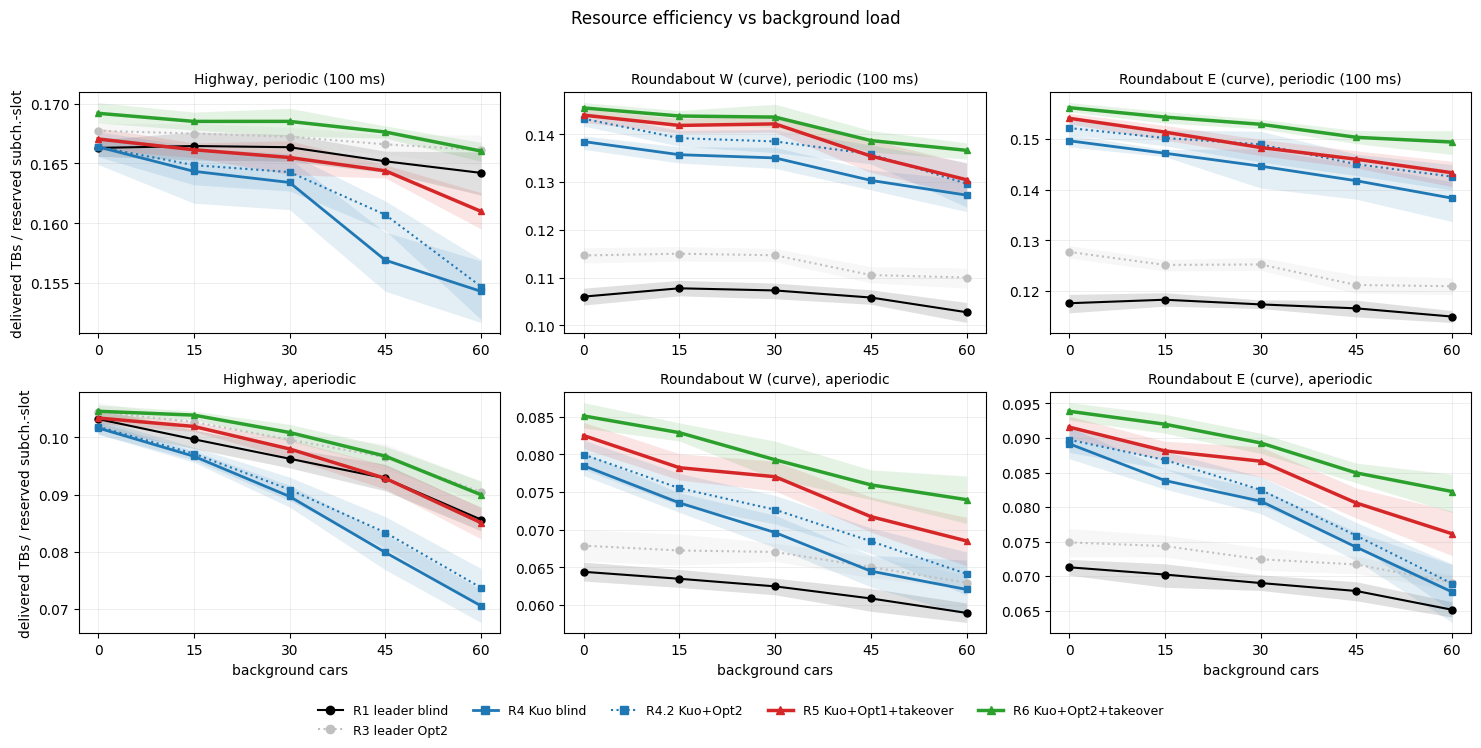

arm                       R1     R2     R3     R4   R4.1   R4.2     R5     R6
sc   tr           nbg                                                        
hwy  aperiodic1tb 0    0.103  0.103  0.104  0.102  0.101  0.102  0.103  0.105
                  60   0.086  0.084  0.090  0.071  0.070  0.074  0.085  0.090
     periodic1tb  0    0.166  0.165  0.168  0.166  0.164  0.166  0.167  0.169
                  60   0.164  0.161  0.166  0.154  0.152  0.155  0.161  0.166
rbt  aperiodic1tb 0    0.064  0.069  0.068  0.078  0.078  0.080  0.082  0.085
                  60   0.059  0.060  0.063  0.062  0.060  0.064  0.069  0.074
     periodic1tb  0    0.106  0.114  0.115  0.139  0.140  0.143  0.144  0.146
                  60   0.103  0.107  0.110  0.127  0.125  0.130  0.131  0.137
rbtE aperiodic1tb 0    0.071  0.075  0.075  0.089  0.088  0.090  0.092  0.094
                  60   0.065  0.065  0.069  0.068  0.066  0.069  0.076  0.082
     periodic1tb  0    0.118  0.125  0.128  0.150  0.151  0.152  0.154  0.156
                  60   0.115  0.118  0.121  0.138  0.134  0.143  0.143  0.149

In [9]:
WIN['tbeq'] = WIN.n_deliv / NMEM
rows = []
for (sc, tr, nbg, arm), g in WIN[WIN.arm.isin(ARMS_ALL)].groupby(['sc', 'tr', 'nbg', 'arm']):
    d = boot_ratio(g, 'n_deliv', 'n_pairs'); e = boot_ratio(g, 'tbeq', 'ss_resv'); t = boot_ratio(g, 'tbeq', 'ss_tx')
    rows.append(dict(sc=sc, tr=tr, nbg=nbg, arm=arm, deliv=d[0], eff_resv=e[0], eff_resv_lo=e[1], eff_resv_hi=e[2],
                     eff_tx=t[0], resv_per_tb=g.ss_resv.sum() / g.n_pkt.sum(), tx_per_tb=g.ss_tx.sum() / g.n_pkt.sum()))
EFF = pd.DataFrame(rows); EFF.to_csv(os.path.join(FIG, 'tab_efficiency_per_load.csv'), index=False)
fig, ax = grid('Resource efficiency vs background load', 'delivered TBs / reserved subch.-slot', 'background cars',
               sharey=False)
for i, tr in enumerate(TRS):
    for j, sc in enumerate(SCS):
        for arm in ARMS_MAIN:
            g = EFF[(EFF.sc == sc) & (EFF.tr == tr) & (EFF.arm == arm)].sort_values('nbg')
            col, ls, lw = STYLE[arm]
            ax[i, j].plot(g.nbg, g.eff_resv, ls=ls, color=col, lw=lw, marker=MARK[arm], ms=5)
            ax[i, j].fill_between(g.nbg, g.eff_resv_lo, g.eff_resv_hi, color=col, alpha=.12, lw=0)
        ax[i, j].set_xticks([0, 15, 30, 45, 60])
legend(fig, ARMS_MAIN); save(fig, 'fig3c_efficiency_vs_load'); plt.show()
display(EFF[EFF.nbg.isin([0, 60])].pivot_table(index=['sc', 'tr', 'nbg'], columns='arm', values='eff_resv')[ARMS_ALL].round(3))


## Figure 4 — Takeover effectiveness
$P_\mathrm{recovery}$ = takeover attempts that rescued at least one member / takeover attempts, per trigger:
**helper NACK** (solid) and **fallback, no helper transmission detected** (dashed), R5 (red) and R6 (green).
x: helper failure probability (same windows as Fig. 2; left) and background load (right column of the second figure).

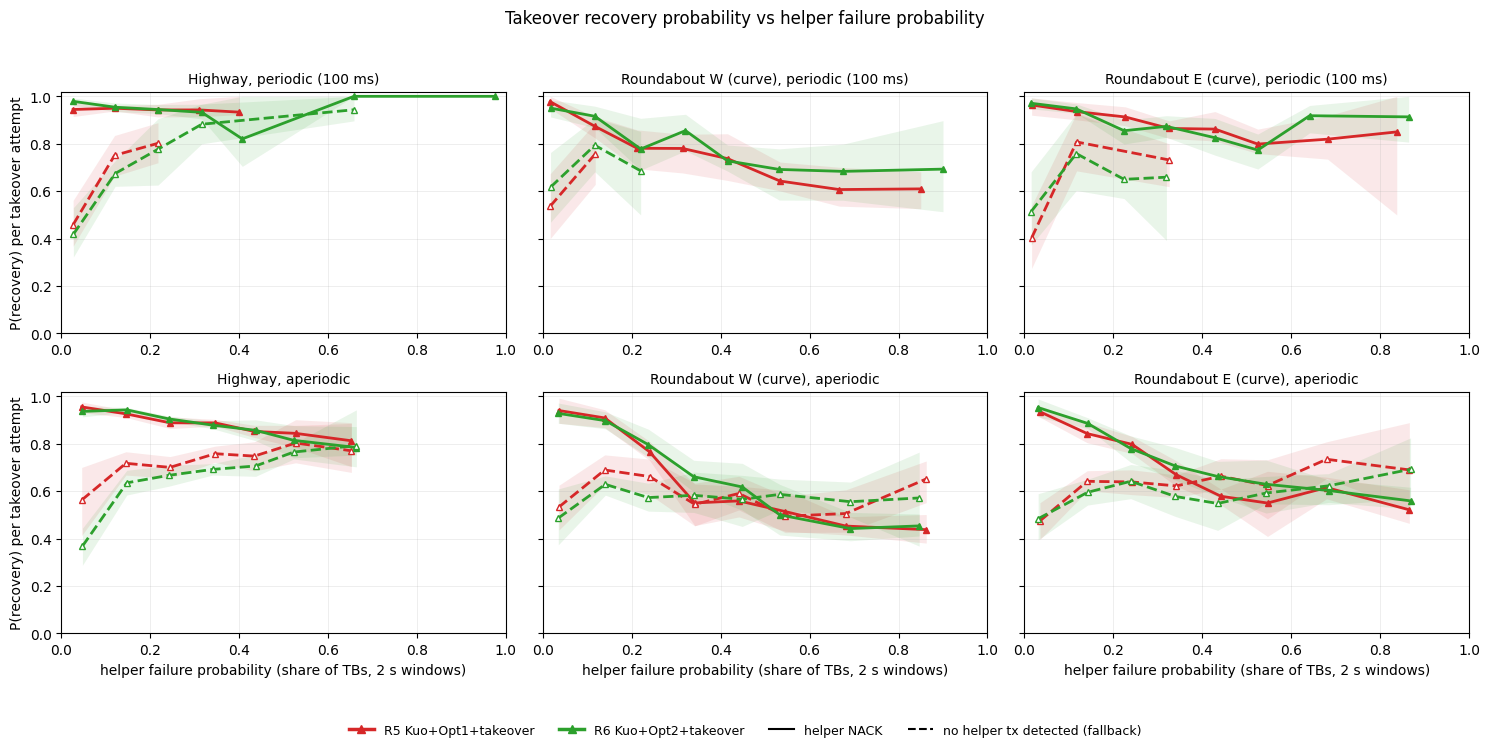

In [10]:
TRIG = {1: ('helper NACK', '-'), 2: ('no helper tx detected (fallback)', '--')}
x = hf_frame(TO_ARMS)
fig, ax = grid('Takeover recovery probability vs helper failure probability', 'P(recovery) per takeover attempt',
               'helper failure probability (share of TBs, 2 s windows)')
rows = []
for i, tr in enumerate(TRS):
    for j, sc in enumerate(SCS):
        a = ax[i, j]
        for arm in TO_ARMS:
            for k, (tn, ls) in TRIG.items():
                g = x[(x.sc == sc) & (x.tr == tr) & (x.arm == arm)]
                pts = []
                for b, gb in g.groupby('hbin'):
                    if gb[f'to{k}_tx'].sum() < 30: continue
                    r, lo, hi = boot_ratio(gb, f'to{k}_useful_tx', f'to{k}_tx')
                    pts.append((gb.hf_w.sum() / gb.n_pkt.sum(), r, lo, hi, gb[f'to{k}_tx'].sum()))
                    rows.append(dict(sc=sc, tr=tr, arm=arm, trigger=tn, hbin=b, hf=pts[-1][0], p_rec=r, lo=lo, hi=hi,
                                     attempts=pts[-1][4]))
                if not pts: continue
                p = pd.DataFrame(pts, columns=['x', 'r', 'lo', 'hi', 'n'])
                col = STYLE[arm][0]
                a.plot(p.x, p.r, ls=ls, color=col, lw=2, marker=MARK[arm], ms=5, mfc=col if k == 1 else 'white')
                a.fill_between(p.x, p.lo, p.hi, color=col, alpha=.1, lw=0)
        a.set_xlim(0, 1); a.set_ylim(0, 1.02)
legend(fig, TO_ARMS, [Line2D([], [], color='k', ls=ls, label=tn) for tn, ls in TRIG.values()])
save(fig, 'fig4_recovery_vs_helper_failure'); plt.show()
pd.DataFrame(rows).to_csv(os.path.join(FIG, 'fig4_recovery_vs_helper_failure.csv'), index=False)


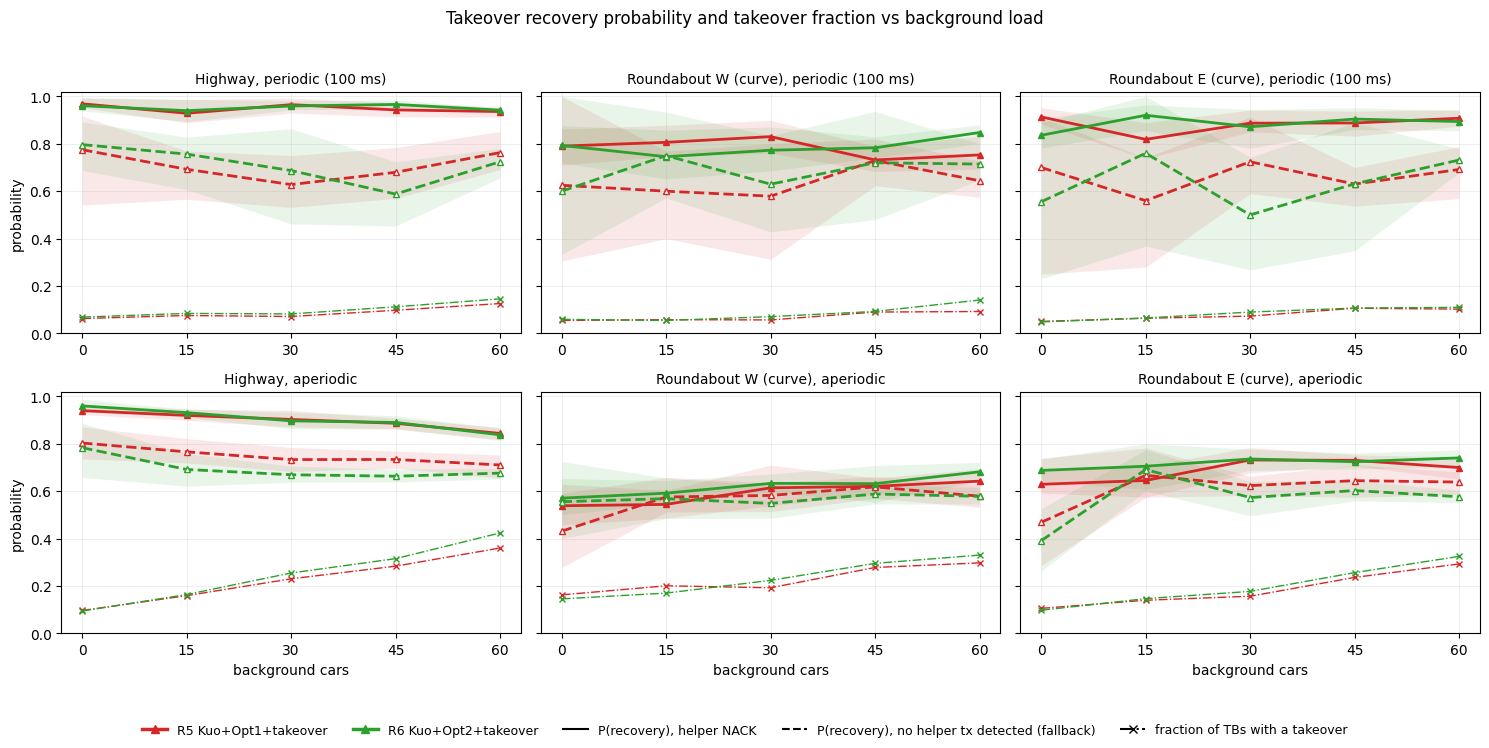

In [11]:
rows = []
for (sc, tr, nbg, arm), g in WIN[WIN.arm.isin(TO_ARMS)].groupby(['sc', 'tr', 'nbg', 'arm']):
    row = dict(sc=sc, tr=tr, nbg=nbg, arm=arm, tbs=g.n_pkt.sum(),
               to_frac=g.to_any_tb.sum() / g.n_pkt.sum(), p_hfail=g.n_hfail.sum() / g.n_helper.sum())
    for k, (tn, _) in TRIG.items():
        r = boot_ratio(g, f'to{k}_useful_tx', f'to{k}_tx')
        rt = boot_ratio(g, f'to{k}_rec_tb', f'to{k}_tb')
        row |= {f't{k}_attempts': g[f'to{k}_tx'].sum(), f't{k}_tb_frac': g[f'to{k}_tb'].sum() / g.n_pkt.sum(),
                f't{k}_p_rec': r[0], f't{k}_p_rec_lo': r[1], f't{k}_p_rec_hi': r[2], f't{k}_p_rec_tb': rt[0],
                f't{k}_member_rescue': g[f'to{k}_rescued'].sum() / max(g[f'to{k}_lacking'].sum(), 1),
                f't{k}_no_lack': g[f'to{k}_nolack_tx'].sum() / max(g[f'to{k}_tx'].sum(), 1)}
    rows.append(row)
TO = pd.DataFrame(rows); TO.to_csv(os.path.join(FIG, 'tab_takeover_per_load.csv'), index=False)

fig, ax = grid('Takeover recovery probability and takeover fraction vs background load', 'probability',
               'background cars', figsize=(15, 7.5))
for i, tr in enumerate(TRS):
    for j, sc in enumerate(SCS):
        a = ax[i, j]
        for arm in TO_ARMS:
            g = TO[(TO.sc == sc) & (TO.tr == tr) & (TO.arm == arm)].sort_values('nbg')
            col = STYLE[arm][0]
            for k, (tn, ls) in TRIG.items():
                a.plot(g.nbg, g[f't{k}_p_rec'], ls=ls, color=col, lw=2, marker=MARK[arm], ms=5,
                       mfc=col if k == 1 else 'white')
                a.fill_between(g.nbg, g[f't{k}_p_rec_lo'], g[f't{k}_p_rec_hi'], color=col, alpha=.1, lw=0)
            a.plot(g.nbg, g.to_frac, ls='-.', color=col, lw=1, marker='x', ms=5)
        a.set_ylim(0, 1.02); a.set_xticks([0, 15, 30, 45, 60])
legend(fig, TO_ARMS, [Line2D([], [], color='k', ls=ls, label='P(recovery), ' + tn) for tn, ls in TRIG.values()]
       + [Line2D([], [], color='k', ls='-.', marker='x', label='fraction of TBs with a takeover')])
save(fig, 'fig4b_recovery_vs_load'); plt.show()


**Recovery table.** Per cell and load: TBs; fraction of TBs with any takeover; per trigger: attempts,
fraction of TBs that trigger it, $P_\mathrm{recovery}$ per attempt (and per TB), member rescue rate (members
rescued / members lacking at the attempt) and the share of attempts with nobody lacking (false alarms).

In [12]:
cols = ['tbs', 'to_frac', 'p_hfail', 't1_attempts', 't1_tb_frac', 't1_p_rec', 't1_p_rec_tb', 't1_member_rescue',
        't1_no_lack', 't2_attempts', 't2_tb_frac', 't2_p_rec', 't2_p_rec_tb', 't2_member_rescue', 't2_no_lack']
for arm in TO_ARMS:
    display(Markdown(f'**{LABEL[arm]}** (t1 = helper NACK, t2 = fallback)'))
    display(TO[TO.arm == arm].set_index(['sc', 'tr', 'nbg'])[cols].round(3))


**R5 Kuo+Opt1+takeover** (t1 = helper NACK, t2 = fallback)

tbs  to_frac  p_hfail  t1_attempts  t1_tb_frac  t1_p_rec  t1_p_rec_tb  t1_member_rescue  t1_no_lack  t2_attempts  t2_tb_frac  t2_p_rec  t2_p_rec_tb  t2_member_rescue  t2_no_lack
sc   tr           nbg                                                                                                                                                                                    
hwy  aperiodic1tb 0    4974    0.097    0.098          463       0.084     0.940        0.988             0.772         0.0           66       0.013     0.803        0.803             0.785       0.167
                  15   4942    0.159    0.156          609       0.115     0.920        0.958             0.749         0.0          222       0.045     0.766        0.766             0.708       0.117
                  30   5007    0.230    0.222          830       0.147     0.902        0.944             0.630         0.0          416       0.083     0.733        0.733             0.581       0.111
                  45   4993    0.284    0.279         1002       0.173     0.886        0.933             0.563         0.0          552       0.111     0.734        0.734             0.543       0.054
                  60   4945    0.360    0.377         1176       0.203     0.844        0.900             0.491         0.0          777       0.157     0.710        0.710             0.441       0.057
     periodic1tb  0    4970    0.063    0.067          285       0.055     0.968        0.993             0.867         0.0           40       0.008     0.775        0.775             0.921       0.225
                  15   4970    0.076    0.077          336       0.063     0.929        0.978             0.840         0.0           65       0.013     0.692        0.692             0.765       0.262
                  30   4970    0.072    0.069          285       0.054     0.965        0.989             0.802         0.0           86       0.017     0.628        0.628             0.689       0.174
                  45   4970    0.098    0.098          384       0.072     0.943        0.981             0.758         0.0          128       0.026     0.680        0.680             0.743       0.227
                  60   4970    0.126    0.131          483       0.091     0.936        0.960             0.701         0.0          177       0.036     0.763        0.763             0.618       0.130
rbt  aperiodic1tb 0    2551    0.163    0.163          520       0.143     0.538        0.750             0.145         0.0           51       0.020     0.431        0.431             0.102       0.020
                  15   2666    0.201    0.199          610       0.161     0.544        0.733             0.170         0.0          106       0.040     0.575        0.575             0.211       0.047
                  30   2714    0.193    0.197          539       0.148     0.614        0.783             0.209         0.0          122       0.045     0.582        0.582             0.239       0.041
                  45   2638    0.278    0.288          635       0.190     0.620        0.745             0.213         0.0          233       0.088     0.618        0.618             0.274       0.047
                  60   2856    0.298    0.305          668       0.189     0.642        0.766             0.215         0.0          311       0.109     0.579        0.579             0.235       0.026
     periodic1tb  0    2548    0.055    0.055          162       0.052     0.790        0.939             0.240         0.0            8       0.003     0.625        0.625             0.200       0.125
                  15   2619    0.058    0.060          165       0.053     0.806        0.942             0.284         0.0           15       0.006     0.600        0.600             0.333       0.133
                  30   2657    0.057    0.057          153       0.050     0.830        0.940             0.275         0.0           19       0.007     0.579        0.579             0.

**R6 Kuo+Opt2+takeover** (t1 = helper NACK, t2 = fallback)

tbs  to_frac  p_hfail  t1_attempts  t1_tb_frac  t1_p_rec  t1_p_rec_tb  t1_member_rescue  t1_no_lack  t2_attempts  t2_tb_frac  t2_p_rec  t2_p_rec_tb  t2_member_rescue  t2_no_lack
sc   tr           nbg                                                                                                                                                                                    
hwy  aperiodic1tb 0    4974    0.095    0.097          445       0.083     0.960        0.988             0.794         0.0           60       0.012     0.783        0.783             0.767       0.167
                  15   4942    0.164    0.150          594       0.110     0.931        0.972             0.761         0.0          269       0.054     0.691        0.691             0.693       0.134
                  30   5007    0.255    0.228          869       0.152     0.896        0.959             0.660         0.0          517       0.103     0.669        0.669             0.560       0.085
                  45   4993    0.315    0.280          925       0.167     0.890        0.934             0.596         0.0          739       0.148     0.663        0.663             0.519       0.070
                  60   4945    0.424    0.383         1226       0.216     0.838        0.889             0.501         0.0         1028       0.208     0.676        0.676             0.431       0.043
     periodic1tb  0    4970    0.069    0.071          303       0.058     0.960        0.990             0.867         0.0           54       0.011     0.796        0.796             0.905       0.204
                  15   4970    0.085    0.087          364       0.069     0.940        0.977             0.836         0.0           78       0.016     0.756        0.756             0.756       0.154
                  30   4970    0.082    0.079          318       0.059     0.959        0.990             0.779         0.0          115       0.023     0.687        0.687             0.736       0.174
                  45   4970    0.112    0.097          380       0.072     0.966        0.981             0.745         0.0          199       0.040     0.588        0.588             0.697       0.216
                  60   4970    0.146    0.135          497       0.094     0.942        0.964             0.735         0.0          261       0.053     0.724        0.724             0.638       0.080
rbt  aperiodic1tb 0    2551    0.146    0.144          475       0.132     0.571        0.777             0.148         0.0           36       0.014     0.556        0.556             0.122       0.056
                  15   2666    0.170    0.162          475       0.135     0.592        0.760             0.186         0.0           95       0.036     0.568        0.568             0.234       0.063
                  30   2714    0.224    0.211          553       0.155     0.633        0.799             0.203         0.0          186       0.069     0.548        0.548             0.200       0.038
                  45   2638    0.296    0.270          554       0.171     0.632        0.744             0.219         0.0          330       0.125     0.588        0.588             0.235       0.039
                  60   2856    0.331    0.305          669       0.192     0.682        0.797             0.235         0.0          396       0.139     0.578        0.578             0.227       0.040
     periodic1tb  0    2548    0.060    0.060          169       0.054     0.793        0.905             0.277         0.0           15       0.006     0.600        0.600             0.152       0.000
                  15   2619    0.055    0.055          161       0.049     0.745        0.914             0.225         0.0           16       0.006     0.750        0.750             0.213       0.000
                  30   2657    0.071    0.068          198       0.061     0.773        0.901             0.245         0.0           27       0.010     0.630        0.630             0.

## Figure 5 — TB delivery latency
CDF of the generation → decode latency over all pairs, a lost pair counted as never delivered (the curve ends at
the delivery probability). Every delivered pair arrives within ~18 ms, far below the PDB (100 ms periodic, 50 ms
aperiodic), so the x-axis stops at the largest observed latency; nothing is delivered between there and the PDB.
One grid at 0 and one at 60 background cars.

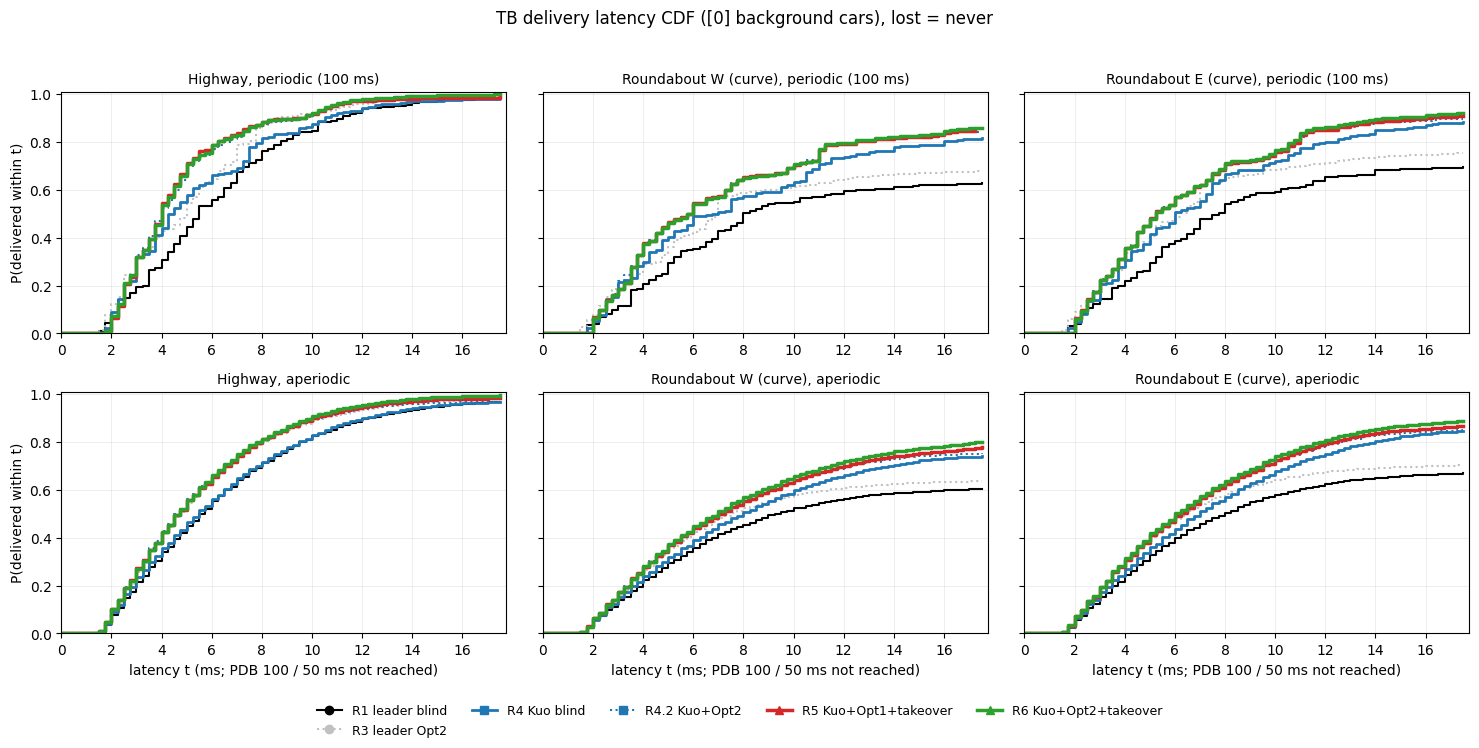

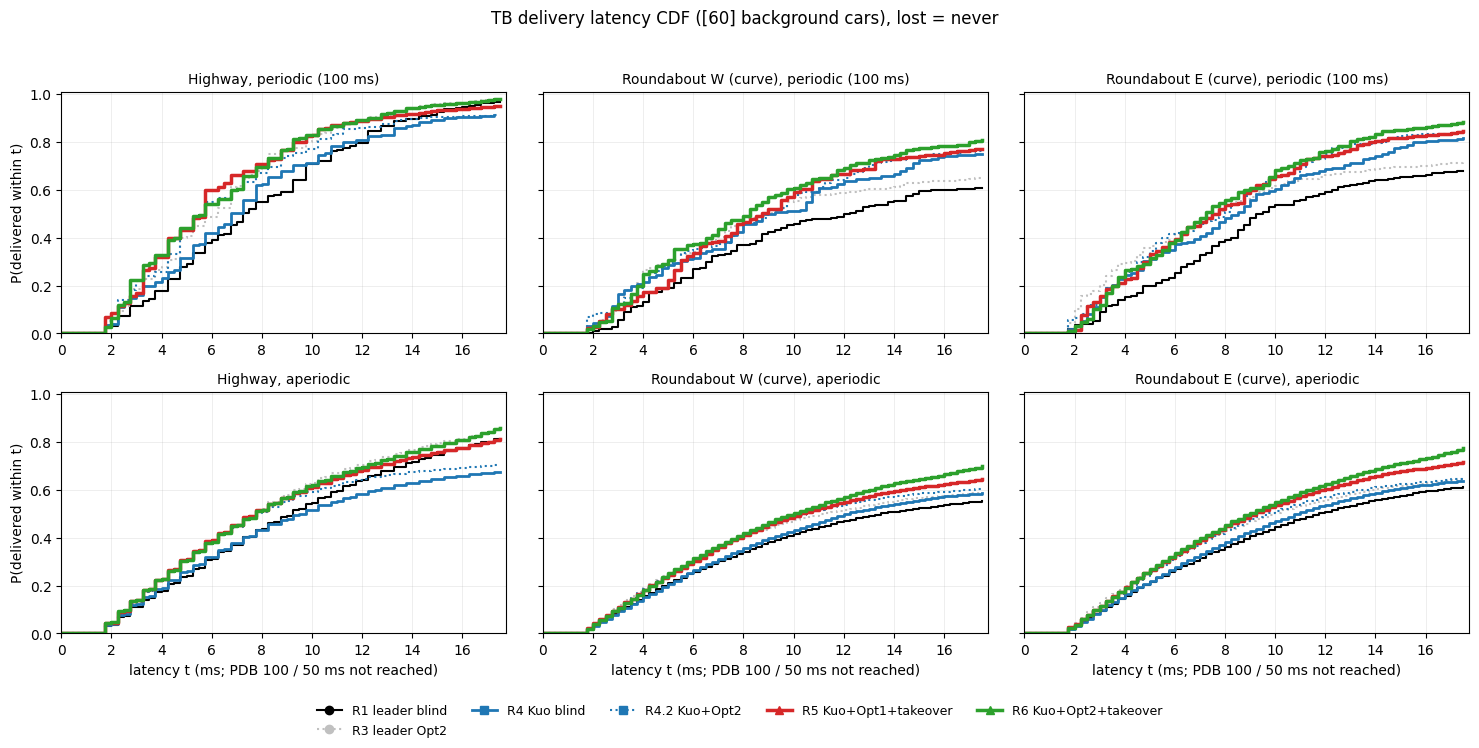

In [13]:
PDBMS = {tr: TD.PDB[tr] * 1e3 for tr in TRS}
def lat_cdf(loads, name):
    fig, ax = grid(f'TB delivery latency CDF ({loads} background cars), lost = never', 'P(delivered within t)',
                   'latency t (ms; PDB 100 / 50 ms not reached)', sharey=True)
    xmax = (LAT[LAT.bin >= 0].bin.max() + 2) * TD.LAT_STEP_MS
    for i, tr in enumerate(TRS):
        for j, sc in enumerate(SCS):
            a = ax[i, j]
            for arm in ARMS_MAIN:
                g = LAT[(LAT.sc == sc) & (LAT.tr == tr) & (LAT.arm == arm) & LAT.nbg.isin(loads)]
                h = g.groupby('bin').n.sum()
                tot = h.sum(); h = h[h.index >= 0].sort_index()
                t = (h.index.values + 1) * TD.LAT_STEP_MS
                col, ls, lw = STYLE[arm]
                a.step(np.r_[0, t], np.r_[0, h.cumsum().values / tot], where='post', ls=ls, color=col, lw=lw)
            a.set_xlim(0, xmax); a.set_ylim(0, 1.01)
    legend(fig, ARMS_MAIN); save(fig, name); plt.show()

lat_cdf([0], 'fig5_latency_cdf_0cars'); lat_cdf([60], 'fig5_latency_cdf_60cars')


**95th-percentile latency** of the delivered pairs vs load (seed CI), and the probability of delivery
within the PDB beside it in the table. p95 over delivered pairs ignores lost ones, so read it with the delivery
probability; `p95_all` treats lost pairs as infinite (NaN when more than 5 % are lost).

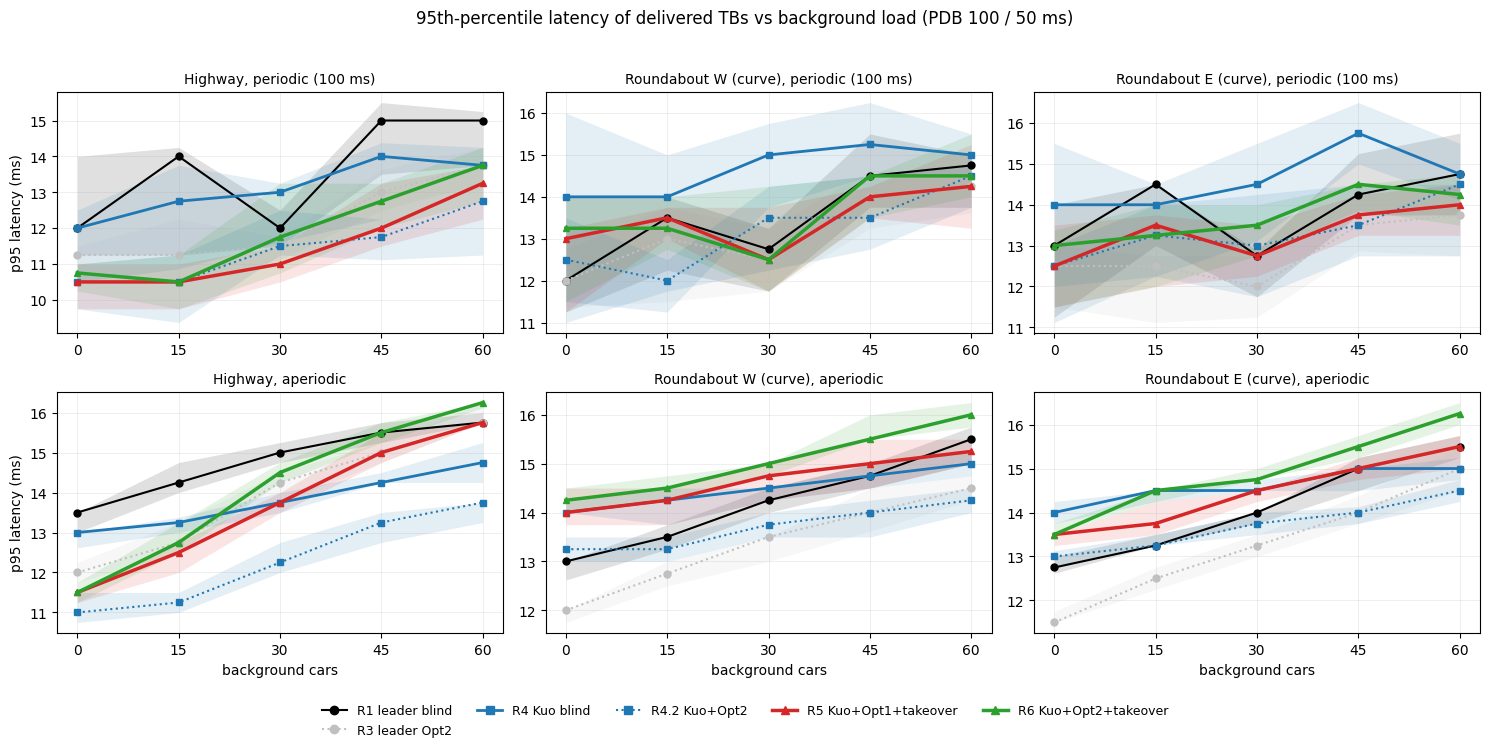

arm                       R1     R2     R3     R4   R4.1   R4.2     R5     R6
sc   tr           nbg                                                        
hwy  aperiodic1tb 0    13.50  11.50  12.00  13.00  11.00  11.00  11.50  11.50
                  60   15.75  14.75  15.75  14.75  12.75  13.75  15.75  16.25
     periodic1tb  0    12.00  10.50  11.25  12.00  10.25  10.50  10.50  10.75
                  60   15.00  12.75  13.75  13.75  11.75  12.75  13.25  13.75
rbt  aperiodic1tb 0    13.00  12.00  12.00  14.00  12.75  13.25  14.00  14.25
                  60   15.50  13.75  14.50  15.00  13.50  14.25  15.25  16.00
     periodic1tb  0    12.00  12.00  12.00  14.00  12.50  12.50  13.00  13.25
                  60   14.75  14.00  14.25  15.00  13.00  14.50  14.25  14.50
rbtE aperiodic1tb 0    12.75  11.50  11.50  14.00  12.75  13.00  13.50  13.50
                  60   15.50  14.00  15.00  15.00  13.50  14.50  15.50  16.25
     periodic1tb  0    13.00  12.25  12.50  14.00  12.50  12.50  12.50  13.00
                  60   14.75  13.25  13.75  14.75  13.25  14.50  14.00  14.25

In [14]:
def p95(h, tot=None, q=.95):
    h = h.sort_index(); c = h.cumsum().values; n = c[-1] if tot is None else tot
    k = np.searchsorted(c, q * n)
    return (h.index.values[k] + 1) * TD.LAT_STEP_MS if k < len(c) else np.nan

rows = []
for (sc, tr, nbg, arm), g in LAT[LAT.arm.isin(ARMS_ALL)].groupby(['sc', 'tr', 'nbg', 'arm']):
    H = g.pivot_table(index='seed', columns='bin', values='n', aggfunc='sum', fill_value=0)
    lost = H.pop(-1) if -1 in H.columns else pd.Series(0, index=H.index)
    tot = H.sum(1) + lost
    hp = H.sum(0)
    bs = []
    for _ in range(300):
        idx = RNG.integers(0, len(H), len(H))
        bs.append(p95(pd.Series(H.values[idx].sum(0), index=H.columns)))
    rows.append(dict(sc=sc, tr=tr, nbg=nbg, arm=arm, p95=p95(hp), p95_lo=np.percentile(bs, 2.5),
                     p95_hi=np.percentile(bs, 97.5), p95_all=p95(hp, tot.sum()), p50=p95(hp, q=.5),
                     deliv=hp.sum() / tot.sum()))
P95 = pd.DataFrame(rows); P95.to_csv(os.path.join(FIG, 'tab_latency_p95.csv'), index=False)
fig, ax = grid('95th-percentile latency of delivered TBs vs background load (PDB 100 / 50 ms)', 'p95 latency (ms)', 'background cars',
               sharey=False)
for i, tr in enumerate(TRS):
    for j, sc in enumerate(SCS):
        for arm in ARMS_MAIN:
            g = P95[(P95.sc == sc) & (P95.tr == tr) & (P95.arm == arm)].sort_values('nbg')
            col, ls, lw = STYLE[arm]
            ax[i, j].plot(g.nbg, g.p95, ls=ls, color=col, lw=lw, marker=MARK[arm], ms=5)
            ax[i, j].fill_between(g.nbg, g.p95_lo, g.p95_hi, color=col, alpha=.12, lw=0)
        ax[i, j].set_xticks([0, 15, 30, 45, 60])
legend(fig, ARMS_MAIN); save(fig, 'fig5b_latency_p95_vs_load'); plt.show()
display(P95[P95.nbg.isin([0, 60])].pivot_table(index=['sc', 'tr', 'nbg'], columns='arm', values='p95')[ARMS_ALL])


## Summary table — the four metrics
Per cell, at 30 cars (CBR ~0.5, the realistic operating point) and 60 cars: TB delivery probability, residual
BLER, delivered TBs per reserved subchannel-slot, p95 latency of delivered TBs, and for R5 / R6 the fraction of
TBs with a takeover and $P_\mathrm{recovery}$ per trigger. Written to `figures/takeover_v3/tab_summary.csv`.

In [15]:
S = EFF.merge(P95[['sc', 'tr', 'nbg', 'arm', 'p95']], on=['sc', 'tr', 'nbg', 'arm'])
S = S.merge(TO[['sc', 'tr', 'nbg', 'arm', 'to_frac', 't1_p_rec', 't2_p_rec']], on=['sc', 'tr', 'nbg', 'arm'], how='left')
S['bler'] = 1 - S.deliv
S = S[S.nbg.isin([30, 60])][['sc', 'tr', 'nbg', 'arm', 'deliv', 'bler', 'eff_resv', 'p95', 'to_frac', 't1_p_rec',
                              't2_p_rec']]
S.to_csv(os.path.join(FIG, 'tab_summary.csv'), index=False)
display(S.set_index(['sc', 'tr', 'nbg', 'arm']).round(3))


deliv   bler  eff_resv    p95  to_frac  t1_p_rec  t2_p_rec
sc   tr           nbg arm                                                             
hwy  aperiodic1tb 30  R1    0.918  0.082     0.096  15.00      NaN       NaN       NaN
                      R2    0.915  0.085     0.096  13.50      NaN       NaN       NaN
                      R3    0.950  0.050     0.100  14.25      NaN       NaN       NaN
                      R4    0.851  0.149     0.090  13.75      NaN       NaN       NaN
                      R4.1  0.839  0.161     0.088  11.75      NaN       NaN       NaN
...                           ...    ...       ...    ...      ...       ...       ...
rbtE periodic1tb  60  R4    0.817  0.183     0.138  14.75      NaN       NaN       NaN
                      R4.1  0.789  0.211     0.134  13.25      NaN       NaN       NaN
                      R4.2  0.842  0.158     0.143  14.50      NaN       NaN       NaN
                      R5    0.846  0.154     0.143  14.00    0.103     0.908     0.692
                      R6    0.882  0.118     0.149  14.25    0.110     0.894     0.731

[96 rows x 7 columns]